# Cognifyz Data Science Internship

## Level 1 – Data Analysis

### Objective
To explore, preprocess, and analyze the restaurant dataset using Python and identify useful patterns through descriptive and geospatial analysis.

### Tasks Completed
1. Data Exploration and Preprocessing
2. Descriptive Analysis
3. Geospatial Analysis

# Level 1 → Task 1: Data Exploration and Preprocessing using your actual dataset.

Cell 1 — Import libraries

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Cell 2 — Load the dataset

In [94]:
df = pd.read_csv("Dataset .csv")

df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


Cell 3 — Find rows and columns

In [95]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9551
Number of columns: 21


Cell 4 — Check missing values

In [96]:
missing_values = df.isnull().sum()

print(missing_values)

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64


Cell 5 — Handle missing values

In [97]:
df["Cuisines"] = df["Cuisines"].fillna("Unknown")

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64


Cell 6 — Check data types

In [98]:
print(df.dtypes)

Restaurant ID             int64
Restaurant Name          object
Country Code              int64
City                     object
Address                  object
Locality                 object
Locality Verbose         object
Longitude               float64
Latitude                float64
Cuisines                 object
Average Cost for two      int64
Currency                 object
Has Table booking        object
Has Online delivery      object
Is delivering now        object
Switch to order menu     object
Price range               int64
Aggregate rating        float64
Rating color             object
Rating text              object
Votes                     int64
dtype: object


Cell 7 — Analyze Aggregate Rating

In [99]:
print(df["Aggregate rating"].describe())

count    9551.000000
mean        2.666370
std         1.516378
min         0.000000
25%         2.500000
50%         3.200000
75%         3.700000
max         4.900000
Name: Aggregate rating, dtype: float64


In [100]:
rating_counts = df["Aggregate rating"].value_counts().sort_index()

print(rating_counts)

Aggregate rating
0.0    2148
1.8       1
1.9       2
2.0       7
2.1      15
2.2      27
2.3      47
2.4      87
2.5     110
2.6     191
2.7     250
2.8     315
2.9     381
3.0     468
3.1     519
3.2     522
3.3     483
3.4     498
3.5     480
3.6     458
3.7     427
3.8     400
3.9     335
4.0     266
4.1     274
4.2     221
4.3     174
4.4     144
4.5      95
4.6      78
4.7      42
4.8      25
4.9      61
Name: count, dtype: int64


Cell 8 — Visualize the rating distribution

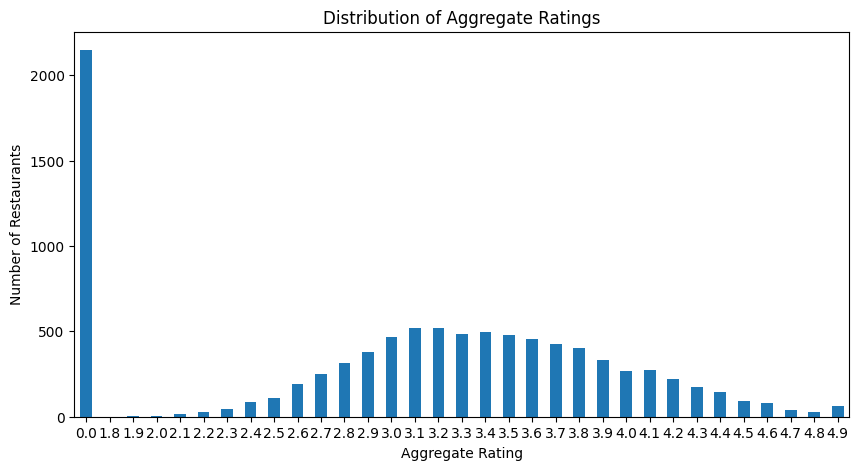

In [101]:
plt.figure(figsize=(10, 5))

df["Aggregate rating"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")
plt.title("Distribution of Aggregate Ratings")
plt.xticks(rotation=0)
plt.show()

Cell 9 — Check class imbalance

In [102]:
rating_percentage = (
    df["Aggregate rating"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(rating_percentage)

Aggregate rating
0.0    22.489792
1.8     0.010470
1.9     0.020940
2.0     0.073291
2.1     0.157052
2.2     0.282693
2.3     0.492095
2.4     0.910899
2.5     1.151712
2.6     1.999791
2.7     2.617527
2.8     3.298084
2.9     3.989111
3.0     4.900010
3.1     5.433986
3.2     5.465396
3.3     5.057062
3.4     5.214114
3.5     5.025652
3.6     4.795309
3.7     4.470736
3.8     4.188043
3.9     3.507486
4.0     2.785049
4.1     2.868810
4.2     2.313894
4.3     1.821799
4.4     1.507696
4.5     0.994660
4.6     0.816668
4.7     0.439745
4.8     0.261753
4.9     0.638677
Name: proportion, dtype: float64


### Level 1 – Task 2: Descriptive Analysis

Cell 1 — Basic statistical measures

In [103]:
# Basic statistical measures for numerical columns

df.describe()

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


Cell 2 — Mean, median and standard deviation separately

In [104]:
print("Mean:")
print(df.mean(numeric_only=True))

print("\nMedian:")
print(df.median(numeric_only=True))

print("\nStandard Deviation:")
print(df.std(numeric_only=True))

Mean:
Restaurant ID           9.051128e+06
Country Code            1.836562e+01
Longitude               6.412657e+01
Latitude                2.585438e+01
Average Cost for two    1.199211e+03
Price range             1.804837e+00
Aggregate rating        2.666370e+00
Votes                   1.569097e+02
dtype: float64

Median:
Restaurant ID           6.004089e+06
Country Code            1.000000e+00
Longitude               7.719196e+01
Latitude                2.857047e+01
Average Cost for two    4.000000e+02
Price range             2.000000e+00
Aggregate rating        3.200000e+00
Votes                   3.100000e+01
dtype: float64

Standard Deviation:
Restaurant ID           8.791521e+06
Country Code            5.675055e+01
Longitude               4.146706e+01
Latitude                1.100794e+01
Average Cost for two    1.612118e+04
Price range             9.056088e-01
Aggregate rating        1.516378e+00
Votes                   4.301691e+02
dtype: float64


Cell 3 — Distribution of Country Code

In [105]:
country_distribution = df["Country Code"].value_counts()

print(country_distribution)

Country Code
1      8652
216     434
215      80
30       60
189      60
214      60
148      40
208      34
14       24
162      22
94       21
166      20
184      20
191      20
37        4
Name: count, dtype: int64


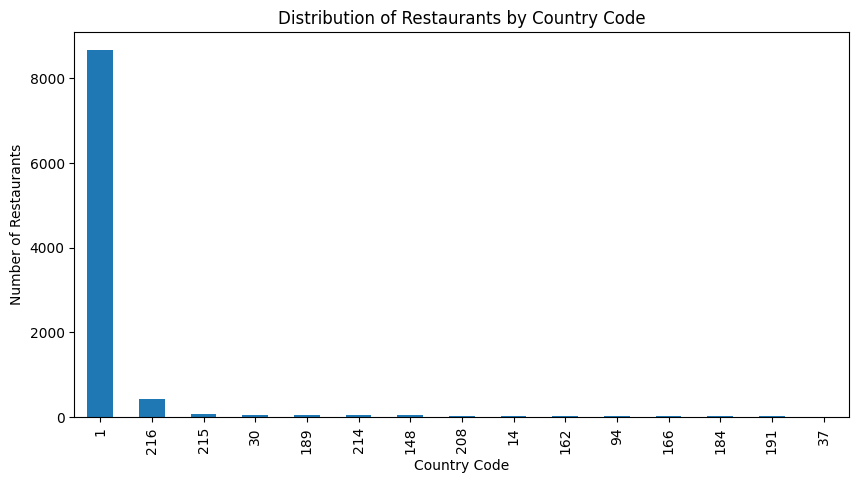

In [106]:
plt.figure(figsize=(10, 5))

country_distribution.plot(kind="bar")

plt.xlabel("Country Code")
plt.ylabel("Number of Restaurants")
plt.title("Distribution of Restaurants by Country Code")
plt.show()

Cell 4 — Distribution of Cities

In [107]:
city_distribution = df["City"].value_counts()

print(city_distribution.head(20))

City
New Delhi          5473
Gurgaon            1118
Noida              1080
Faridabad           251
Ghaziabad            25
Bhubaneshwar         21
Lucknow              21
Ahmedabad            21
Amritsar             21
Guwahati             21
Rio de Janeiro       20
Bras�_lia            20
Albany               20
Doha                 20
Cape Town            20
Manchester           20
London               20
Edinburgh            20
Birmingham           20
Wellington City      20
Name: count, dtype: int64


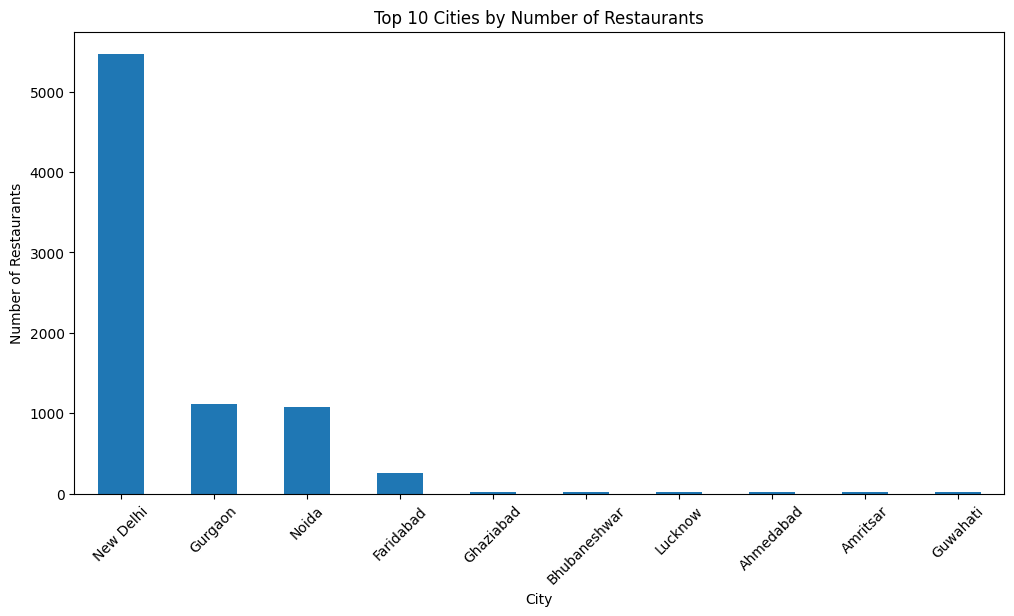

In [108]:
plt.figure(figsize=(12, 6))

city_distribution.head(10).plot(kind="bar")

plt.xlabel("City")
plt.ylabel("Number of Restaurants")
plt.title("Top 10 Cities by Number of Restaurants")
plt.xticks(rotation=45)
plt.show()

Cell 5 — Distribution of Cuisines

In [109]:
cuisine_distribution = df["Cuisines"].value_counts()

print(cuisine_distribution.head(20))

Cuisines
North Indian                      936
North Indian, Chinese             511
Fast Food                         354
Chinese                           354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Pizza, Fast Food                  131
Chinese, Fast Food                118
Mithai, Street Food               116
South Indian                      112
Bakery, Fast Food                 108
Chinese, North Indian             105
Mughlai                           103
Ice Cream, Desserts                83
North Indian, Fast Food            74
Ice Cream                          74
Name: count, dtype: int64


Cell 6 — Top 10 cuisines

In [110]:
top_cuisines = df["Cuisines"].value_counts().head(10)

print("Top 10 Cuisines:")
print(top_cuisines)

Top 10 Cuisines:
Cuisines
North Indian                      936
North Indian, Chinese             511
Fast Food                         354
Chinese                           354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: count, dtype: int64


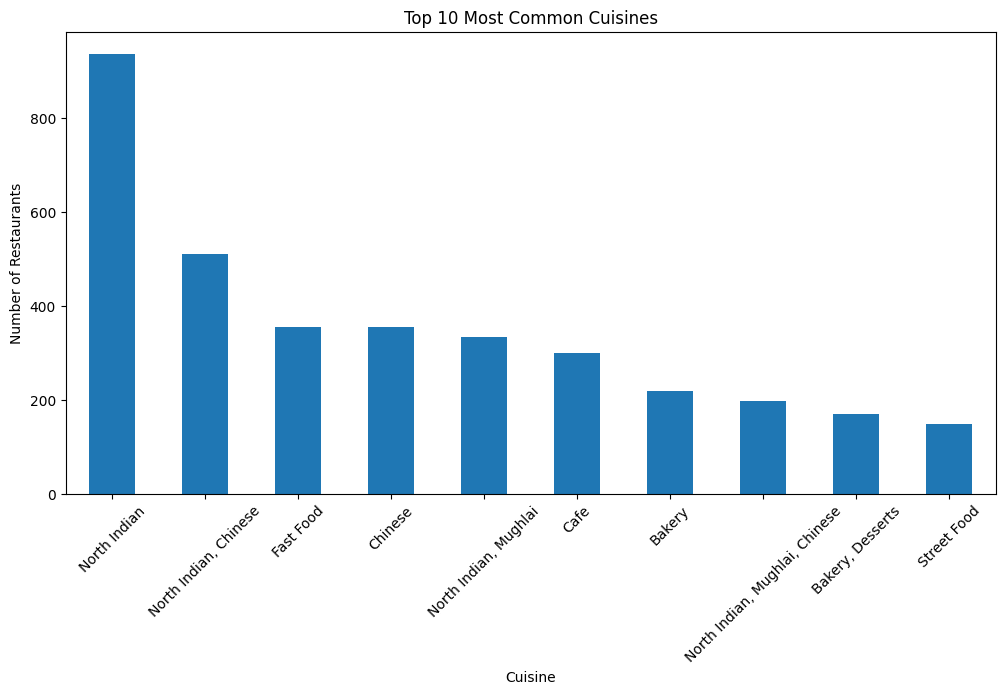

In [111]:
plt.figure(figsize=(12, 6))

top_cuisines.plot(kind="bar")

plt.xlabel("Cuisine")
plt.ylabel("Number of Restaurants")
plt.title("Top 10 Most Common Cuisines")
plt.xticks(rotation=45)
plt.show()

Cell 7 — Cities with the highest number of restaurants

In [112]:
top_cities = df["City"].value_counts().head(10)

print("Top 10 Cities with the Highest Number of Restaurants:")
print(top_cities)

Top 10 Cities with the Highest Number of Restaurants:
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Lucknow           21
Ahmedabad         21
Amritsar          21
Guwahati          21
Name: count, dtype: int64


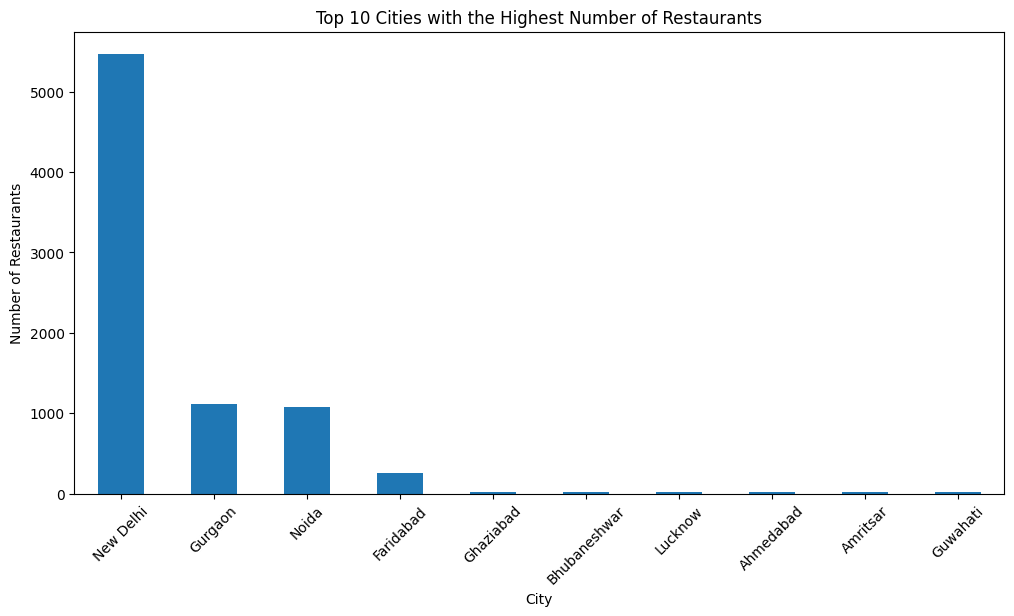

In [113]:
plt.figure(figsize=(12, 6))

top_cities.plot(kind="bar")

plt.xlabel("City")
plt.ylabel("Number of Restaurants")
plt.title("Top 10 Cities with the Highest Number of Restaurants")
plt.xticks(rotation=45)
plt.show()

Level 1 – Task 3: Geospatial Analysis

Cell 1 — Import libraries

In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("Dataset .csv")

df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


Cell 2 — Check latitude and longitude

In [115]:
print("Latitude missing values:", df["Latitude"].isnull().sum())
print("Longitude missing values:", df["Longitude"].isnull().sum())

print("\nLatitude range:")
print(df["Latitude"].min(), "to", df["Latitude"].max())

print("\nLongitude range:")
print(df["Longitude"].min(), "to", df["Longitude"].max())

Latitude missing values: 0
Longitude missing values: 0

Latitude range:
-41.330428 to 55.97698

Longitude range:
-157.948486 to 174.8320893


Cell 3 — Plot restaurant locations

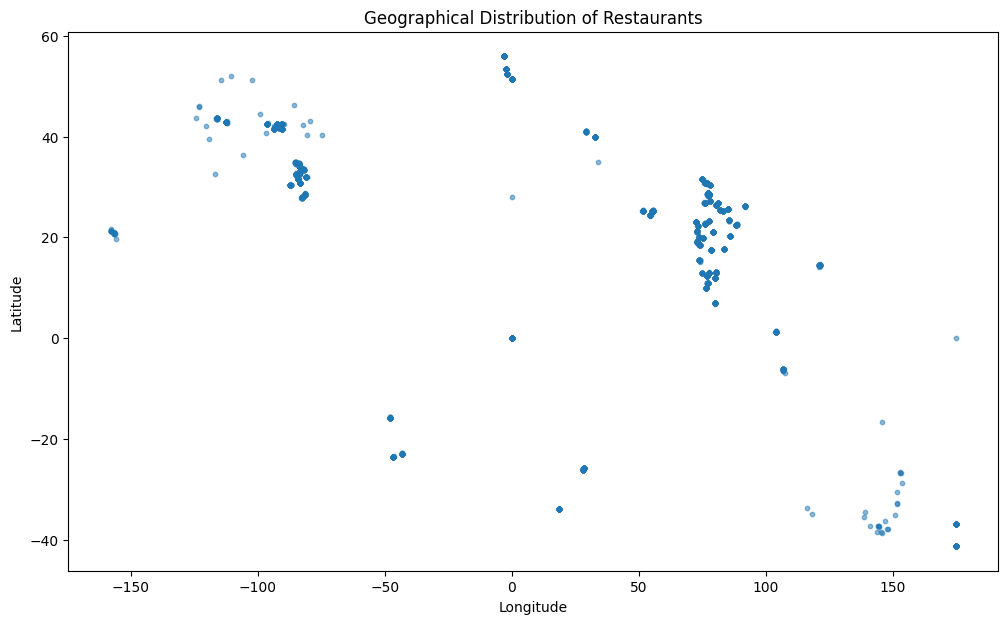

In [116]:
plt.figure(figsize=(12, 7))

plt.scatter(
    df["Longitude"],
    df["Latitude"],
    alpha=0.5,
    s=10
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Restaurants")

plt.show()

Cell 4 — Top cities by number of restaurants

In [117]:
city_counts = df["City"].value_counts().head(10)

print("Top 10 Cities by Number of Restaurants:")
print(city_counts)

Top 10 Cities by Number of Restaurants:
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Lucknow           21
Ahmedabad         21
Amritsar          21
Guwahati          21
Name: count, dtype: int64


Cell 5 — Visualize restaurant distribution by city

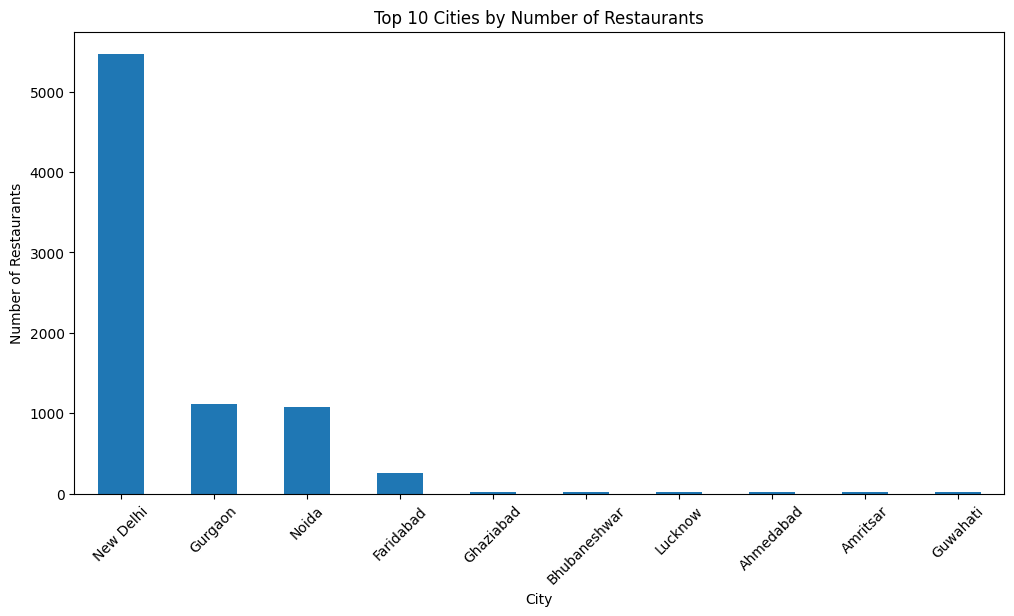

In [118]:
plt.figure(figsize=(12, 6))

city_counts.plot(kind="bar")

plt.xlabel("City")
plt.ylabel("Number of Restaurants")
plt.title("Top 10 Cities by Number of Restaurants")

plt.xticks(rotation=45)
plt.show()

Cell 6 — Restaurant distribution by country

In [119]:
country_counts = df["Country Code"].value_counts()

print("Restaurant Distribution by Country Code:")
print(country_counts)

Restaurant Distribution by Country Code:
Country Code
1      8652
216     434
215      80
30       60
189      60
214      60
148      40
208      34
14       24
162      22
94       21
166      20
184      20
191      20
37        4
Name: count, dtype: int64


Cell 7 — Visualize country distribution

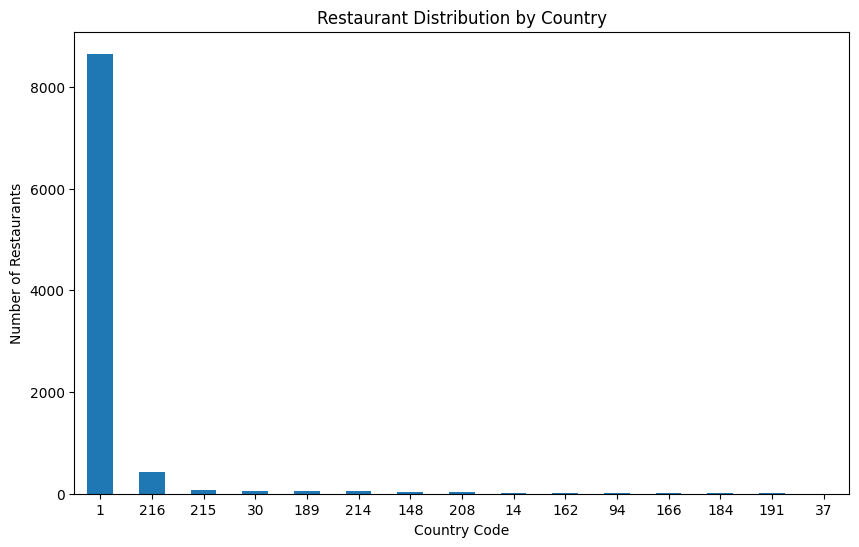

In [120]:
plt.figure(figsize=(10, 6))

country_counts.plot(kind="bar")

plt.xlabel("Country Code")
plt.ylabel("Number of Restaurants")
plt.title("Restaurant Distribution by Country")

plt.xticks(rotation=0)
plt.show()

Cell 8 — Location vs rating

In [121]:
city_rating = (
    df.groupby("City")["Aggregate rating"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 Cities by Average Restaurant Rating:")
print(city_rating.head(10))

Top 10 Cities by Average Restaurant Rating:
City
Inner City          4.900000
Quezon City         4.800000
Makati City         4.650000
Pasig City          4.633333
Mandaluyong City    4.625000
Beechworth          4.600000
London              4.535000
Taguig City         4.525000
Secunderabad        4.500000
Lincoln             4.500000
Name: Aggregate rating, dtype: float64


Cell 9 — Plot average rating by city

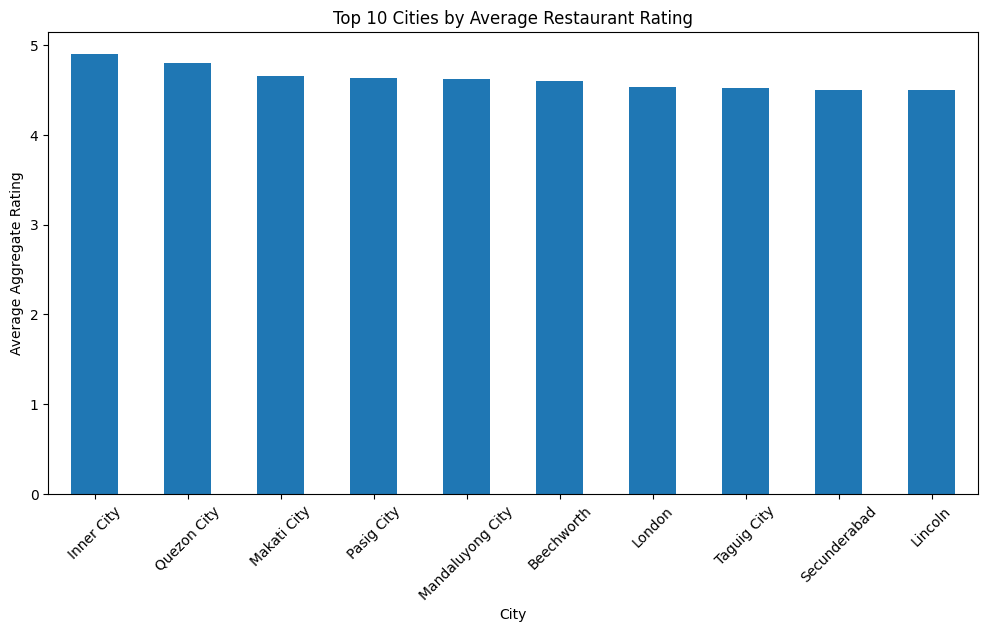

In [122]:
plt.figure(figsize=(12, 6))

city_rating.head(10).plot(kind="bar")

plt.xlabel("City")
plt.ylabel("Average Aggregate Rating")
plt.title("Top 10 Cities by Average Restaurant Rating")

plt.xticks(rotation=45)
plt.show()

Cell 10 — Correlation between location and rating

In [123]:
correlation = df[
    ["Latitude", "Longitude", "Aggregate rating"]
].corr()

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
                  Latitude  Longitude  Aggregate rating
Latitude          1.000000   0.043207          0.000516
Longitude         0.043207   1.000000         -0.116818
Aggregate rating  0.000516  -0.116818          1.000000


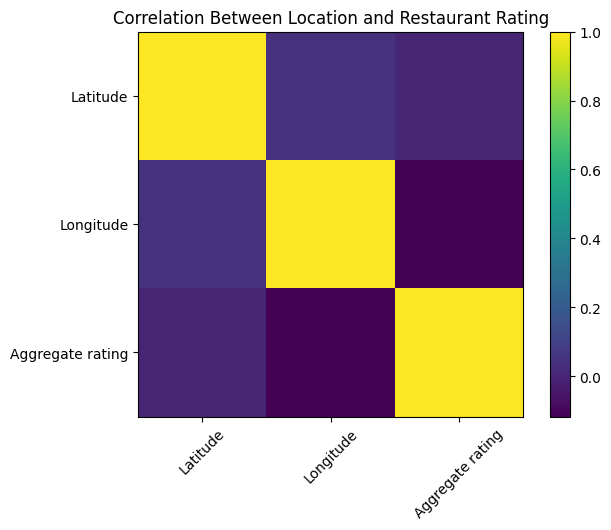

In [124]:
plt.figure(figsize=(7, 5))

plt.imshow(correlation, interpolation="nearest")

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Between Location and Restaurant Rating")

plt.show()

## Conclusion

The Level 1 tasks provided an understanding of the restaurant dataset through data exploration, preprocessing, descriptive analysis, and geospatial analysis. The analysis helped identify important patterns in restaurant ratings, locations, cities, countries, and cuisines.